
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/13_Lab_PinnsII.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pylab as plt
import plotly.graph_objects as go
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Diferenciación automática

Permite calcular las derivadas exactas sin tener que recurrir a derivación simbólica o aproximaciones numéricas. En su lugar, se descompone la función en operaciones elementales (sumas, multiplicaciones, funciones trigonométricas, etc) y se aplica la regla de la cadena.

In [2]:
# operaciones básicas para la dff automática 

def suma(a, da, b, db):
  return a+b, da+db

def producto(a, da, b, db):
  return a*b, a*db + da*b

def division(a, da, b, db):
  return a/b, (b*da - a*db)/(b**2)

def seno(a, da):
  return np.sin(a), da*np.cos(a)

def coseno(a, da):
  return np.cos(a), -da*np.sin(a)


def tanhiperbolica(a, da):
    valor = np.tanh(a)
    return valor, (1 - valor**2)*da


def tanhiperbolica2(a, da, d2a):
    A, dA = tanhiperbolica(a, da)
    A2, dA2 = producto(A, dA, A, dA)
    G, dG = suma(1, 0, -A2, -dA2)
    _, d2A = producto(G, dG, da, d2a)
    return A, dA, d2A

### Ejemplo 1: 

Computemos la deriva de $f(x) = x^2$ en el punto $x$. 

Podemos escribir $f(x) = x \cdot x$, donde cada término $x$ tiene un 1 como factor. Así la derivada con la función producto es

In [3]:
x = 2.5
derivadaX = producto(x, 1, x, 1)
derivadaX

(6.25, 5.0)

El resultado exacto es claramente $f'(x) = 2 x$, y por tanto $f'(2.5) = 5.0$.

### Ejemplo 2
$f(x) = (2x+1)^2 = (2x +1) (2x + 1)$. Aquí tenemos varias operaciones.

 Primero, el producto $2x$ , calculamos su derivada, teniendo en cuenta que la deviada de $2$ es $0$ y la derivada de $x$ es $1$. 

 Segudno, tenemos la suma $u + 1$, con $u = 2x$, y $du$ calculada en el paso anterior. 

 Finalmente, hacemos el producto de $c \times c$, con $c = u + 1$. 

In [4]:
u, du = producto(2, 0, x, 1)
c, dc = suma(u, du, 1, 0)
producto(c, dc, c, dc)

(36.0, 24.0)

La derivada exacta es f'(x) = 4(2x + 1)$, evaluada en $x = 2.5$ es $24$. 

### Ejemplo 3 

Para una función más compleja tenemos: 
$
f(x)=\sin\!\bigl(\cos(x^2)\bigr),
$

$
u=x^2,\qquad u'=2x,
$

$
v=\cos(u),\qquad v'=-\sin(u)\,u',
$


$
f=\sin(v),\qquad f'=\cos(v)\,v'.
$

Su derivada exacta es

$
f'(x)=-2x\,\sin(x^2)\,\cos\!\bigl(\cos(x^2)\bigr).
$

In [5]:
x = np.linspace(0, 2*np.pi, 10000)
u, du = producto(x, 1, x, 1)
c, dc = coseno(u, du)
r, dr = seno(c, dc)

f = lambda x: -2*x*np.sin(x**2)*np.cos(np.cos(x**2))

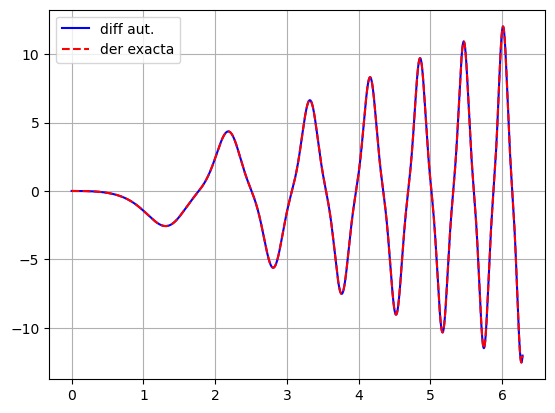

In [6]:
plt.plot(x, dr, color='blue', label = 'diff aut.')
plt.plot(x, f(x), '--', color='red', label='der exacta')
plt.grid()
plt.legend()
plt.show()

### Aplicación a redes neuronales

Supongamos que tenemos dos neuronas conectadas y queremos computar una diferenciacion automática cuyas funciones de activación son tanh:

\begin{equation}
\frac{da_2}{dx}
=
\frac{da_2}{dz_2}
\frac{dz_2}{da_1}
\frac{da_1}{dz_1}
\frac{dz_1}{dx}
=
(1-\tanh Z_2^2)\,w_2\,(1-\tanh Z_1^2)\,w_1.
\end{equation}



#### Derivada analítica 

Se hace el forward y se evalúa la expresión anterior que corresponde a la derivada analítica. En sistemas de muchas capas y neuronas, es impráctico. 

In [7]:
x = 0.8
w = 0.1
b = 0.1

z = w*x + b
a1 = np.tanh(z)

z2 = w*a1 + b
a2 = np.tanh(z2)

derivada = (1-(np.tanh( z2))**2) * (1-(np.tanh( z))**2)*w**2
derivada

np.float64(0.009549719627467191)

#### Usando diff. automática 

In [8]:
t1, dt1 = producto(w, 0, x, 1)
z, dz = suma(t1, dt1, b, 0)
a1, da1 = tanhiperbolica(z, dz)

t2, dt2 = producto(w, 0, a1, da1)
z2, dz2 = suma(t2, dt2, b, 0)
a2, da2 = tanhiperbolica(z2, dz2)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

#### Reducción a una función

En cada nuerona se aplican tres operaciones: producto, suma y tanh, que se preiten en cada capa. Podemos agruparlas en una función,

In [9]:
def dneurona(x, dx, w, b):
  t1, dt1 = producto(w, 0, x, dx)
  z, dz = suma(t1, dt1, b, 0)
  a1, da1 = tanhiperbolica(z, dz)
  return a1, da1

In [10]:
a1, da1 = dneurona(x, 1, w, b)
a2, da2 = dneurona(a1, da1, w, b)
a2, da2

(np.float64(0.11726608605144122), np.float64(0.009549719627467191))

## Difusión de calor en una placa cuadrada

Considere una placa homogénea de lado $L$, sin fuentes internas
de calor y con temperatura uniforme a través de su espesor.
Su difusividad térmica es constante:

$$
\alpha=\frac{k}{\rho c_p},
$$

donde $k$ es la conductividad térmica, $\rho$ la densidad y
$c_p$ el calor específico.

Determine la temperatura $T(x,y,t)$ en el dominio
$(x,y)\in(0,L)^2$, para $t>0$, mediante la ecuación de calor:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2T}{\partial x^2}
+
\frac{\partial^2T}{\partial y^2}
\right).
$$

Los cuatro bordes permanecen a temperatura constante $T_b$:

$$
T(0,y,t)=T(L,y,t)=T(x,0,t)=T(x,L,t)=T_b.
$$

La temperatura inicial es:

$$
T(x,y,0)=T_b+\Delta T
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right),
$$

donde $\Delta T>0$ es la diferencia inicial entre la temperatura
del centro y la de los bordes.

Aproximar $T(x,y,t)$ mediante una PINN,
minimizando el residual de la ecuación y los errores en las
condiciones iniciales y de frontera. Comparar el resultado
con la solución analítica:

$$
T(x,y,t)=T_b+\Delta T
e^{-2\alpha\pi^2t/L^2}
\sin\left(\frac{\pi x}{L}\right)
\sin\left(\frac{\pi y}{L}\right).
$$

In [11]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [12]:
## Solución análitica 
def T(x, y, t, **params):

  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


### Discretización

La placa cuadrada se discretiza en una malla espacial de tamaño $30 \times 30$, con puntos separados por $dx = dy = 0.0345$. Para el tiempo se considera un tiempo final de $500$, con un paso dado por el límite máximo de establidad de Euler, sobre el cuál se usa el $90 \% $ de ese valor como margen de seguridad.

In [13]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny)) # plano nx,ny para cada valor nt 

#### condiciones de frontera

In [14]:
'''se recorren todos los puntos de la red para cada tiempo
a cada punto de un borde se le asigna un valor de temperatura
 constante, en este caso Tb = 300 C'''

def Temp_border():
  for k in range(0, nt):
    for i   in range(0, nx):
      for j in range(0, ny):
        if(i == 0):
          Temperatura[k][0, j] = Tb
        elif(j == 0):
          Temperatura[k][i, 0] = Tb
        elif(i == nx-1):
          Temperatura[k][nx-1, j] = Tb
        elif(j == ny-1):
          Temperatura[k][i, ny-1] = Tb
        else:
          Temperatura[k][i, j] = 0
  return Temperatura

In [15]:
#x = np.linspace(0, 1, 100)
#y = np.linspace(0, 1, 100)
#t = np.linspace(0, 800, 1000)

X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)

In [16]:
# temperatura en los bordes 
np.min(Temperatura[0])

np.float64(300.0)

In [17]:
# temperatura en el centro
np.max(Temperatura[0,:,:])

np.float64(399.706897857718)

### Planos de Temperatura 

Se implementa la función para obtener la distribicuión de la temperatura de la placa en diferentes instántes de tiempo

In [18]:
def graficar_planos(
    Temperatura, Lx, Ly,
    tiempos=None,
    n_planos=5,
    opacidad=0.5
):
    nt, nx, ny = Temperatura.shape

    x = np.linspace(0, Lx, nx)
    y = np.linspace(0, Ly, ny)
    X, Y = np.meshgrid(x, y, indexing="ij")

    titulo_t = "Tiempo [s]" if tiempos is not None else "Índice de tiempo"
    tiempos = np.arange(nt) if tiempos is None else np.asarray(tiempos)

    # Seleccionar pocos tiempos, incluyendo el primero y el último.
    indices = np.unique(
        np.linspace(0, nt - 1, min(n_planos, nt), dtype=int)
    )

    # Escala de colores común.
    Tmin = float(np.nanmin(Temperatura))
    Tmax = float(np.nanmax(Temperatura))

    if Tmin == Tmax:
        Tmin -= 0.5
        Tmax += 0.5

    fig = go.Figure()

    for j, k in enumerate(indices):
        fig.add_trace(go.Surface(
            x=np.full(X.shape, tiempos[k], dtype=float),
            y=X,
            z=Y,
            surfacecolor=Temperatura[k],
            colorscale="Jet",
            cmin=Tmin,
            cmax=Tmax,
            opacity=opacidad,
            showscale=(j == 0),
            colorbar=dict(title="Temperatura [°C]"),
            lighting=dict(ambient=1, diffuse=0, specular=0),
            name=f"Temperatura[{k}]",
            hovertemplate=(
                "Tiempo / índice = %{x:.3f}<br>"
                "x = %{y:.3f} m<br>"
                "y = %{z:.3f} m<br>"
                "T = %{surfacecolor:.2f} °C"
                "<extra>%{fullData.name}</extra>"
            )
        ))

    fig.update_layout(
        height=650,
        scene=dict(
            xaxis_title=titulo_t,
            yaxis_title="x [m]",
            zaxis_title="y [m]",
            aspectmode="manual",
            aspectratio=dict(x=1.6, y=1, z=Ly / Lx),
            camera=dict(eye=dict(x=-1.7, y=-1.7, z=0.8))
        ),
        margin=dict(l=0, r=0, b=0, t=30)
    )

    return fig

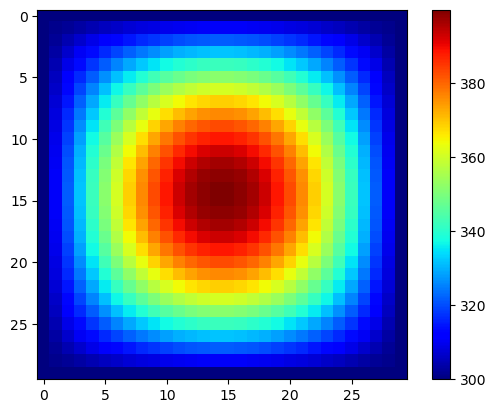

In [19]:
# distribución inicial de temperaturas 

plt.imshow(Temperatura[0], cmap='jet')
plt.colorbar()
plt.show()

In [20]:
# calcular con la solución análitica en todo el intarvalo de tiempo t
for i in range(1, len(t)):
  Temperatura[i,:,:] =  T(X, Y, t[i], **params)

np.shape(Temperatura)

(188, 30, 30)

### Visualización de planos de temperatura en función del tiempo

In [21]:
fig = graficar_planos(
    Temperatura, Lx, Ly,
    n_planos=10,
    opacidad=0.5
)
fig.show()

### Animación

In [22]:
n_frames =len(Temperatura)# min(100), Temperatura.shape[0])

fig, ax = plt.subplots(figsize=(6, 5))

imagen = ax.imshow(
    Temperatura[0],
    cmap="jet",
    vmin=np.nanmin(Temperatura[:n_frames]),
    vmax=np.nanmax(Temperatura[:n_frames])
)

fig.colorbar(imagen, ax=ax, label="Temperatura [°C]")
titulo = ax.set_title("Temperatura[0]")

def actualizar(i):
    imagen.set_data(Temperatura[i])
    titulo.set_text(f"Temperatura[{i}]")
    return imagen, titulo

animacion = FuncAnimation(
    fig,
    actualizar,
    frames=n_frames,
    interval=1,
    repeat=True
)

plt.close(fig)
display(HTML(animacion.to_jshtml()))


# Physics-Informed Machine Learning (PIML)

Consideremos la ecuación de difusión de calor en dos dimensiones:

$$
\frac{\partial T}{\partial t}
=
\alpha\left(
\frac{\partial^2 T}{\partial x^2}
+
\frac{\partial^2 T}{\partial y^2}
\right),
$$

donde $\alpha$ es la difusividad térmica.

## 1. Modelo neuronal con tangente hiperbólica

Consideremos una neurona definida por:

$$
Z_\theta(x,y,t)=\theta_1 x+\theta_2 y+\theta_3 t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=\tanh(Z_\theta).
$$

## 2. Modelo neuronal con activación gaussiana

Conservando una sola neurona, podemos incorporar una dependencia espacial cuadrática:

$$
Z_\theta(x,y,t)=
\theta_1(x-x_c)^2+
\theta_2(y-y_c)^2+
\theta_3t+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=e^{-Z_\theta}.
$$

Esta función permite representar distribuciones localizadas de temperatura, con un máximo espacial cuando los coeficientes cuadráticos son positivos.

## 3. Función de coste física

Para cualquiera de los dos modelos, definimos el residuo:

$$
R_\theta(x_i,y_i,t_i)=
\frac{\partial T_\theta}{\partial t}
-
\alpha\left(
\frac{\partial^2T_\theta}{\partial x^2}
+
\frac{\partial^2T_\theta}{\partial y^2}
\right).
$$

La función de coste es:

$$
J_{\mathrm{fisica}}(\theta)=
\frac{1}{M}\sum_{i=1}^{M}
R_\theta(x_i,y_i,t_i)^2.
$$

Las derivadas se calculan mediante diferenciación automática.

## 4. Condiciones iniciales y de frontera

Si conocemos las temperaturas iniciales y de frontera, incorporamos sus errores:

$$
J(\theta)=
J_{\mathrm{fisica}}
+
J_{\mathrm{inicial}}
+
J_{\mathrm{frontera}}.
$$

Finalmente, los parámetros se actualizan mediante descenso de gradiente:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-\eta\nabla_\theta J.
$$

Ambos modelos tienen cuatro parámetros entrenables: tres pesos y un sesgo. La diferencia principal está en la función utilizada para representar el campo de temperaturas.


Para entrenar la red construiremos un vector de entrada como sigue:
https://www.sciencedirect.com/science/article/pii/S0021999118307125

\begin{equation}
\mathbf Q=
\begin{pmatrix}
x_1&y_1&t_0\\
x_2&y_2&t_0\\
\vdots&\vdots&\vdots\\
x_N&y_N&t_0
\end{pmatrix}
\end{equation}




In [23]:
Lx = 1.0       # Longitud en x [m]
Ly = 1.0       # Longitud en y [m]
Tb = 300     # Temperatura fija de los bordes [°C]
delta_T = 100.0 # Diferencia inicial centro-bordes [°C]

alpha = 1e-4  # Difusividad térmica [m²/s]

#parametros físicos del problema 
params = {'Lx': Lx, 'Ly': Ly, 'Tb': Tb, "delta":delta_T ,'alpha': alpha}

In [24]:
def T(x, y, t, **params):
  Lx = params['Lx']
  Ly = params['Ly']
  Tb = params['Tb']
  alpha = params['alpha']
  u = np.sin(np.pi*x/Lx)*np.sin(np.pi*y/Ly)
  return Tb + delta_T* np.exp(-2*alpha*np.pi**2*t/(Lx*Ly))*u


Se utiliza la misma discretización del caso anterior: malla espacial  $ 30 \times 30$ y $n_t = 188$ instantes entre 0 y 500. $n_x \times n_y \times n_z$ es el total de puntos. 

In [25]:
nx, ny = 30, 30
tiempo_final = 500.0

x = np.linspace(0, params["Lx"], nx)
y = np.linspace(0, params["Ly"], ny)
dx = x[1] - x[0]
dy = y[1] - y[0]

# Límite de estabilidad para diferencias finitas con Euler explícito
dt_max = 1 / (
    2 * params["alpha"] * (1 / dx**2 + 1 / dy**2)
)
# Margen de seguridad del 10 %
nt = int(np.ceil(tiempo_final / (0.9 * dt_max))) + 1

t = np.linspace(0, tiempo_final, nt)
dt = t[1] - t[0]
X, Y = np.meshgrid(x, y, indexing="ij")
nx, ny, nt = len(x), len(y), len(t)
Temperatura = np.zeros((nt,nx, ny))

### Condición de bordes

Usamos la función Temp_border del caso anterior.

In [26]:
''' Fijamos la temperatura constane en los bordes y en el tiempo inicial
usamos la condición dada por la solución exacta'''

X, Y = np.meshgrid(x, y, indexing="ij")
Temperatura = Temp_border()
Temperatura[0,:,:] =  T(X, Y, 0, **params)
#print(Temperatura)

tf = np.max(t) - np.min(t)
tf # Tiempo final

np.float64(500.0)

In [27]:
X1 = x.reshape((len(x), 1))
Y1 = y.reshape((len(y), 1))
tk = t.reshape((len(t), 1))/np.max(t)

### Matriz de evaluación

Definimos la matriz $Q$ con todos los puntos de evaluación, definida anteriormente.Tiene una dimensión de $((30\times 30 \times 188), 3)$

In [28]:
Q=np.zeros((30*30*nt, 3))
p=0
for k in range(0, nt):
  for i in range(0, nx):
    for j in range(0, ny):
      Q[p] = np.array([ t[k],x[i], y[j]])
      p=p+1

In [29]:
Q.shape

(169200, 3)

### Selección de los bordes

In [30]:
# separar las columnas de Q , cada una con dimensión (nt, nx, ny)
tt = Q[:,0].reshape(nt, nx, ny)
xx = Q[:,1].reshape(nt, nx, ny)
yy = Q[:,2].reshape(nt, nx, ny)

# se construye una mascara booleana para los bordes 
borde = (
    np.isclose(xx, x[0]) |
    np.isclose(xx, x[-1]) |
    np.isclose(yy, y[0]) |
    np.isclose(yy, y[-1])
)
borde_concatenado = borde.reshape(-1)

In [31]:
Q_borde = Q[borde_concatenado]
Q_borde

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 3.44827586e-02],
       [0.00000000e+00, 0.00000000e+00, 6.89655172e-02],
       ...,
       [5.00000000e+02, 1.00000000e+00, 9.31034483e-01],
       [5.00000000e+02, 1.00000000e+00, 9.65517241e-01],
       [5.00000000e+02, 1.00000000e+00, 1.00000000e+00]], shape=(21808, 3))

In [32]:
T_borde = Temperatura[borde].reshape(-1, 1)
print(Q_borde.shape)
print(T_borde.shape)

(21808, 3)
(21808, 1)


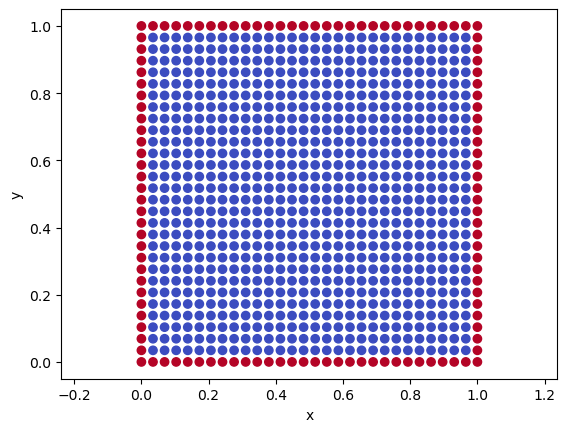

In [33]:
plt.scatter(xx[0], yy[0], c=borde[0], cmap="coolwarm")
plt.xlabel("x")
plt.ylabel("y")
plt.axis("equal")
plt.show()

### Condicion inicial

Se extraen los puntos de $Q$ con $t = t_0 = 0$. Así, tenemos $30 \times 30 = 900$ puntos en el tiempo inicial (900, 3),  y el valor de la temperatura que conocemos en esos puntos (900, 1).

In [34]:
inicial = np.isclose(tt, t[0])
Q_ini = Q[inicial.reshape(-1)]
T_ini = Temperatura[inicial].reshape(-1, 1)
print(Q_ini.shape)
print(T_ini.shape)

(900, 3)
(900, 1)


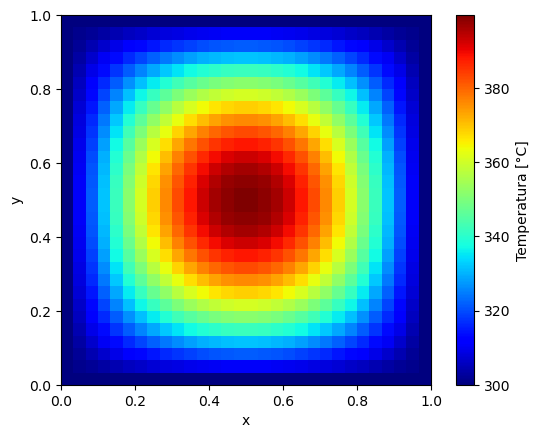

In [35]:
plt.imshow(
    Temperatura[0].T,
    origin="lower",
    extent=[x[0], x[-1], y[0], y[-1]],
    cmap="jet"
)

plt.colorbar(label="Temperatura [°C]")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [36]:
#Normalizacion
delta_T = max(np.max(np.abs(T_ini - Tb)), 1.0)
u_ini = (T_ini - Tb) / delta_T
u_borde = (T_borde - Tb) / delta_T

In [37]:
interior = ~borde & ~inicial

Q_f = Q[interior.reshape(-1)]

### Entrenar el modelo

Con el modelo 1 de $tanh$. Suponemos que la salida de la neurona es nuestra función parámetrica que da solución a la ecuación de calor.  $T_\theta(x,y,t)=\tanh(Z_\theta).
$


Se hace la diferenciación automática (backward propagation) para obtener las derivadas respecto a $t$, $x$ e $y$. Así podemos calcular el resiudo. 

Posteriormente construimos la función de costo para la ecuación $T_theta(x, y,t)$ , las condiciones iniciales y de frontera. La idea es mínimizar $J_theta$ respecto a los parámetros $\omega_t$, $\omega_x$, $\omega_y$ y $b$. 

In [38]:
# Inicialización
np.random.seed(42)

perdidas = []
eta = 0.01

W = np.random.random((3, 1))
B = np.random.random((1, 1))

# Derivadas de Z respecto a (wt, wx, wy, b)
dZ = np.column_stack((Q_f, np.ones(len(Q_f))))
dZ_ini = np.column_stack((Q_ini, np.ones(len(Q_ini))))
dZ_borde = np.column_stack((Q_borde, np.ones(len(Q_borde))))

et = np.array([1, 0, 0, 0])

for i in range(1000):
    if(i%50==0):
      print(i)

    # Forward
    Z = Q_f @ W + B
    A = np.tanh(Z)

    # Derivadas
    _, dA_dt, _ = tanhiperbolica2(Z, W[0, 0], 0)
    _, _, d2A_dx2 = tanhiperbolica2(Z, W[1, 0], 0)
    _, _, d2A_dy2 = tanhiperbolica2(Z, W[2, 0], 0)
    R = dA_dt - alpha * (d2A_dx2 + d2A_dy2)
    J_fisica = np.mean(R**2)

    # Derivadas de tanh respecto a Z
    A, G, H = tanhiperbolica2(Z, 1, 0)
    _, K = producto(-2*A, -2*G, G, H)

    # Pesos
    wt, wx, wy = W[:, 0]

    # Gradientes del residuo
    C = wt*H - alpha*(wx**2 + wy**2)*K

    dR = C*dZ

    dR[:, 0] += G[:, 0]
    dR[:, 1] -= 2*alpha*wx*H[:, 0]
    dR[:, 2] -= 2*alpha*wy*H[:, 0]

    # Gradiente de la función de coste
    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.tanh(Q_ini @ W + B)
    J_ini = np.mean((A_ini - u_ini)**2)
    ei = (A_ini - u_ini) * (1 - A_ini**2)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condiciones de frontera
    A_borde = np.tanh(Q_borde @ W + B)
    J_borde = np.mean((A_borde - u_borde)**2)
    eb = (A_borde - u_borde) * (1 - A_borde**2)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    # Función de coste total
    J = J_fisica + J_ini + J_borde

    # Actualización de los parámetros
    W[:, 0] -= eta * gradiente[:3]
    B[0, 0] -= eta * gradiente[3]

    perdidas.append(J)

0
50
100
150
200
250
300
350
400
450
500
550
600
650
700
750
800
850
900
950


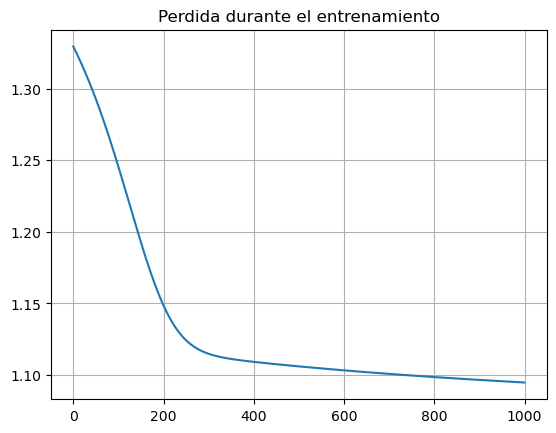

In [39]:
plt.title("Perdida durante el entrenamiento")
plt.plot(np.array(perdidas))
plt.grid()
plt.show()

El modelo no logra ajustarse del todo bien a las condiciones iniciales y de frontera. Intuitivamente, el modelo se $tanh$ se queda corto para aproximar la solución real que contiene soluciones exponenciales imaginarias (oscilantes). 

Sin embargo, podemos visualizar la solución obtenida. Para esto hacemos 

$$ T_{PINN } = T_b + \Delta T  \tanh(Q W + B) $$

In [40]:
Z = Q@W+B
A = np.tanh(Z)
Temperatura_PINN = Tb + delta_T*A.reshape(nt, nx, ny)
A = A.reshape(nx, ny,nt)

In [41]:

fig = graficar_planos(
    Temperatura_PINN,
    Lx,
    Ly,
    tiempos=t,
    n_planos=5
)

fig.show()

Se observa que no se cumple las condiciones iniciales ni de frontera. Para $t > 0$, la placa se calienta de manera uniforme. Esto se debe a que Z toma valores grandes  y $\tan(Z)$ se satura. 

In [42]:
# Implementar el mismo codigo para una funcion de la forma:
#

### Neurona con activación Gaussiana 

En este caso, suponemos 
$$
Z_\theta(x,y,t)=
\theta_1(x-x_c)^2+
\theta_2(y-y_c)^2+
\theta_3 \tau+b.
$$

La temperatura se aproxima mediante:

$$
T_\theta(x,y,t)=e^{-Z_\theta}.
$$

Aquí el tieempo se normaliza para evitar saturación: $\tau = (t - t_0)/t_f$. Los términos cuadráticos se anulan en el centro de la plaza y crecen hacia los bordes. de modo que $e^{-Z}$ es máxima en el centro y se reduce hacia los bordes. Además la placa se enfría dada la forma exponencial. 

In [43]:
def caracteristicas(Q):
    tau = (Q[:, 0:1] - t[0]) / tf
    xi = (Q[:, 1:2] - x[0]) / Lx - 0.5
    yi = (Q[:, 2:3] - y[0]) / Ly - 0.5

    P = np.hstack((tau, xi**2, yi**2))

    return P, xi, yi

P, xi, yi = caracteristicas(Q)
P_ini, _, _ = caracteristicas(Q_ini)
P_borde, _, _ = caracteristicas(Q_borde)

In [44]:
W = np.random.random((3, 1))
B = np.random.random((1, 1))

Z = P @ W + B
A = np.exp(-Z)

In [45]:
def exponencial(a, da):
    A = np.exp(a)
    return A, A*da

def exponencial2(a, da, d2a):
    A, dA = exponencial(a, da)
    _, d2A = producto(A, dA, da, d2a)
    return A, dA, d2A

In [46]:
wt, wx, wy = W[:, 0]

_, dA_dt, _ = exponencial2(-Z, -wt, 0)

_, _, d2A_dx2 = exponencial2(
    -Z, -2*wx*xi, -2*wx
)

_, _, d2A_dy2 = exponencial2(
    -Z, -2*wy*yi, -2*wy
)

In [47]:
ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2

J_fisica = np.mean(R**2)

In [48]:
np.random.seed(42)

W = np.random.random((3, 1))
B = np.random.random((1, 1))

eta = 0.01
perdidas = []

ax = alpha * tf / Lx**2
ay = alpha * tf / Ly**2

dZ = np.column_stack((P, np.ones(len(P))))
dZ_ini = np.column_stack((P_ini, np.ones(len(P_ini))))
dZ_borde = np.column_stack((P_borde, np.ones(len(P_borde))))

et, ex, ey = np.eye(4)[:3]

for i in range(1000):

    # Forward
    Z = P @ W + B
    A = np.exp(-Z)

    wt, wx, wy = W[:, 0]

    # Derivadas automáticas respecto a las coordenadas
    _, dA_dt, _ = exponencial2(-Z, -wt, 0)

    _, _, d2A_dx2 = exponencial2(
        -Z, -2*wx*xi, -2*wx
    )

    _, _, d2A_dy2 = exponencial2(
        -Z, -2*wy*yi, -2*wy
    )

    R = dA_dt - ax*d2A_dx2 - ay*d2A_dy2
    J_fisica = np.mean(R**2)

    # Gradientes del residuo respecto a W y B
    px, dpx = producto(2*xi, 0, wx, ex)
    py, dpy = producto(2*yi, 0, wy, ey)

    Fx, dFx = producto(px, dpx, px, dpx)
    Fx, dFx = suma(Fx, dFx, -2*wx, -2*ex)

    Fy, dFy = producto(py, dpy, py, dpy)
    Fy, dFy = suma(Fy, dFy, -2*wy, -2*ey)

    C, dC = suma(-wt, -et, -ax*Fx, -ax*dFx)
    C, dC = suma(C, dC, -ay*Fy, -ay*dFy)

    _, dR = producto(A, -A*dZ, C, dC)

    gradiente = np.mean(2*R*dR, axis=0)

    # Condición inicial
    A_ini = np.exp(-(P_ini @ W + B))

    J_ini = np.mean((A_ini - u_ini)**2)

    ei = (A_ini - u_ini) * (-A_ini)
    gradiente += 2*np.mean(ei*dZ_ini, axis=0)

    # Condición de frontera
    A_borde = np.exp(-(P_borde @ W + B))

    J_borde = np.mean((A_borde - u_borde)**2)

    eb = (A_borde - u_borde) * (-A_borde)
    gradiente += 2*np.mean(eb*dZ_borde, axis=0)

    # Coste total
    J = J_fisica + J_ini + J_borde
    perdidas.append(J)

    # Actualizar parámetros
    W[:, 0] -= eta*gradiente[:3]
    B[0, 0] -= eta*gradiente[3]

    if i % 50 == 0:
        print(i, J)

0 0.20794333370467535
50 0.16953420784536372
100 0.1524483378853501
150 0.14333168240336178
200 0.13790447188370888
250 0.13442161282876935
300 0.13205678759894376
350 0.13037641605880035
400 0.12913526140946588
450 0.12818644528168052
500 0.12743794867553102
550 0.12682999497542846
600 0.1263225822810427
650 0.12588827265537395
700 0.12550785111114748
750 0.12516762189790456
800 0.12485767476402859
850 0.1245707448160829
900 0.12430144606265493
950 0.12404574611832306


In [72]:
A = np.exp(-(P @ W + B))

Temperatura_PINN = Tb + delta_T*A.reshape(nt, nx, ny)

fig = graficar_planos(
    Temperatura_PINN,
    Lx,
    Ly,
    tiempos=t,
    n_planos=5
)

fig.show()

El modelo funciona bastante bien y reproduce la evolución de la solución analítica. Vemos que la temperatura es máxima en el centro y decrece hacia los bordes, y la paca se enfría con el tiempo, respetando en todo momento las condiciones de borde. 